## Titanic Dataset Analysis

I'm going to be exploring three questions: 
1)How did survival vary by sex? 
2)How did survival vary by passenger class? 
3)Were first class females/males more likely to survive than those in lower classes?

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

In [47]:
df= pd.read_csv("train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [48]:
df.shape

(891, 12)

In [49]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [50]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Age, Cabin and embarked are irrelevant for the current data analysis, so their missing values shall not be dealt with.

## Exploratory Data Analysis

## Sex

In [51]:
print("Males that were in the boat:",(df['Sex']=='male').sum())
print("Females that were in the boat:",(df['Sex']=='female').sum())

Males that were in the boat: 577
Females that were in the boat: 314


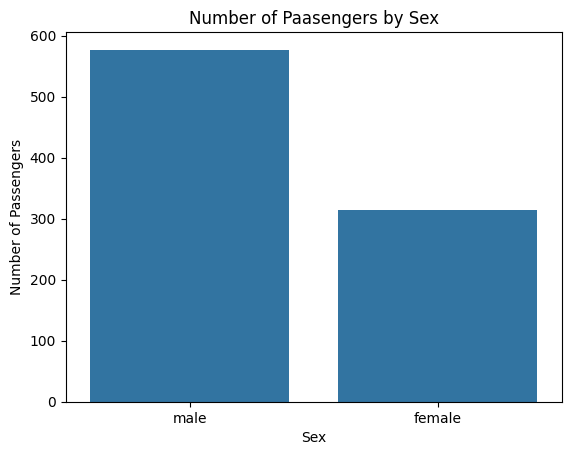

In [61]:
sns.countplot(data=df, x='Sex')
plt.title('Number of Paasengers by Sex')
plt.xlabel('Sex')
plt.ylabel('Number of Passengers')
plt.show()

The analysis shows that there were more male passengers on the boat than female passengers

In [62]:
df.groupby('Sex')['Survived'].sum()

Sex
female    233
male      109
Name: Survived, dtype: int64

In [63]:
#calculating survival rates of each group
df.groupby('Sex')['Survived'].mean()*100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

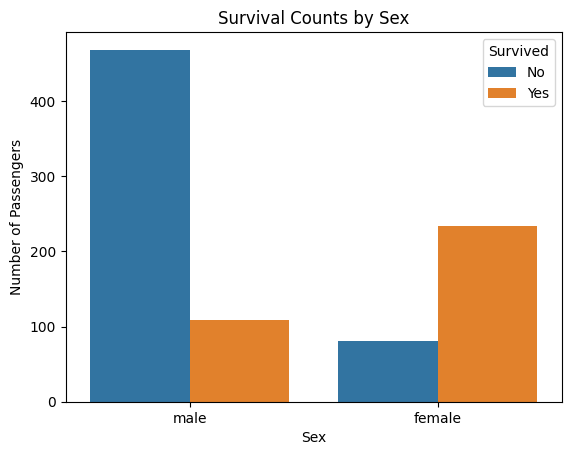

In [64]:
sns.countplot(data=df, x='Sex', hue='Survived')
plt.title('Survival Counts by Sex')
plt.xlabel('Sex')
plt.ylabel('Number of Passengers')
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

The analysis shows that female passengers were most likely to survive than male passengers.

## P Class

In [65]:
df['Pclass'].value_counts().sort_index()

Pclass
1    216
2    184
3    491
Name: count, dtype: int64

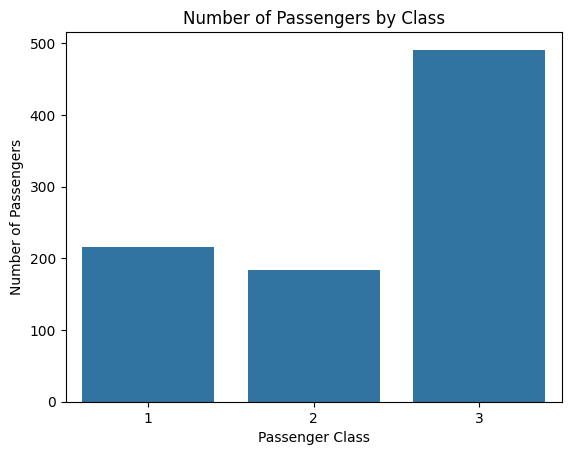

In [71]:
sns.countplot(data=df, x='Pclass')
plt.title('Number of Passengers by Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.show()

In [72]:
df.groupby('Pclass')['Survived'].sum()

Pclass
1    136
2     87
3    119
Name: Survived, dtype: int64

In [73]:
df.groupby('Pclass')['Survived'].mean()*100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

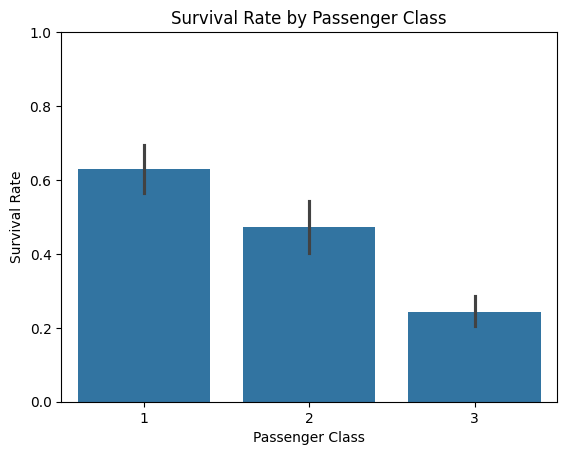

In [77]:
sns.barplot(data=df, x='Pclass', y='Survived')
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.ylim(0,1)
plt.show()

The findings show that passengers in the upper classes were more likely to survive than those in lower class.

## Exploring survival rates for different sexes in different classes

In [78]:
df.groupby(['Sex', 'Pclass']).size()

Sex     Pclass
female  1          94
        2          76
        3         144
male    1         122
        2         108
        3         347
dtype: int64

In [79]:
df.groupby(['Sex', 'Pclass'])['Survived'].sum()

Sex     Pclass
female  1         91
        2         70
        3         72
male    1         45
        2         17
        3         47
Name: Survived, dtype: int64

In [80]:
df.groupby(['Sex', 'Pclass'])['Survived'].mean()*100

Sex     Pclass
female  1         96.808511
        2         92.105263
        3         50.000000
male    1         36.885246
        2         15.740741
        3         13.544669
Name: Survived, dtype: float64

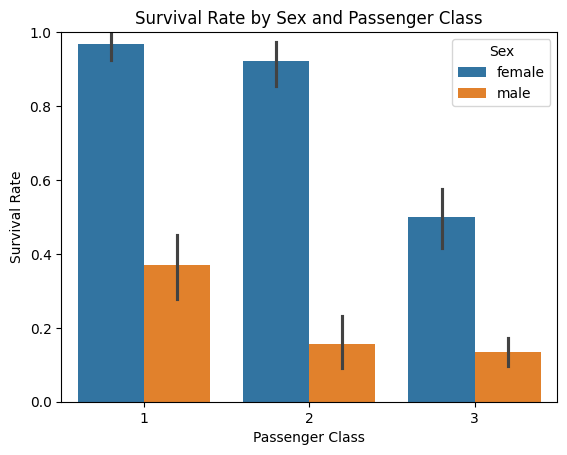

In [81]:
sns.barplot(
    data=df,
    x='Pclass',
    y='Survived',
    hue='Sex'
)

plt.title('Survival Rate by Sex and Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.ylim(0,1)
plt.legend(title='Sex')
plt.show()

The findings show that female passengers in the upper class have a higher survival rate than those in lower classes. 

## Conclusion

How did survival vary by sex? and How did survival vary by passenger class?

The data suggested that females had a higher survival rate than males and that those in upper passenger class have a higher survival rate than those in lower class